micrograd from scratch yay

In [54]:
import math
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [55]:
def f(x):
    return 3 * x**2 - 4 * x + 5

In [56]:
f(3)

20

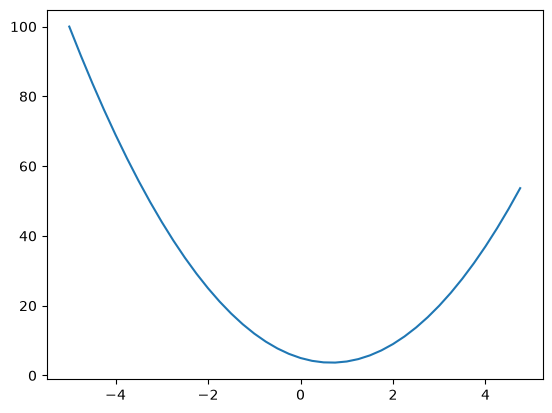

In [57]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [58]:
h = 0.001
x = 3.0
d = (f(x + h) - f(x)) / h
d
# Here d = derivative of the function f() with respect to x

14.00300000000243

In [59]:
# les get more complex
a = 2.0
b = -3.0
c = 10.0
# d = now more complex function with multiple variables (i.e. 3: a, b & c)
d = a * b + c
print(d)

4.0


In [60]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

In [61]:
# differentiative with respect to a i.e. d/da
d1 = a * b + c
a += h
d2 = a * b + c

print("d1", d1)
print("d2", d2)
print("slope", (d2 - d1) / h)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [62]:
# differentiative with respect to b i.e. d/db
d1 = a * b + c
b += h
d2 = a * b + c

print("d1", d1)
print("d2", d2)
print("slope", (d2 - d1) / h)

d1 3.999699999999999
d2 3.99990001
slope 2.0001000000124947


In [63]:
# differentiative with respect to a i.e. d/da
d1 = a * b + c
a += h
d2 = a * b + c

print("d1", d1)
print("d2", d2)
print("slope", (d2 - d1) / h)

d1 3.99990001
d2 3.999600019999999
slope -2.9999000000113796


In [93]:
# now moving on to the values which are building blocks
class Value:
    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0  # grad = gradient
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data = {self.data})"

    # addition operation
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        # behaviour of backward for addition operations i.e. simply pass gradient as it is to backward nodes
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __neg__(self):
        return self * -1

    # self - other
    def __sub__(self, other):
        return self+(-other)

    # multiplication operation
    # case of self * other
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        # behaviour of backward for multiplication operations
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    # case of other * self
    def __rmul__(self, other): # case of 2*a which simply calls a * 2, weird quirky python behaviour
        return self*other

    # power function for case of self ** other i.e. self^other
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), f'**{other}')

        def _backward():
            self.grad+= other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out 

    # case of self / other
    def __truediv__(self, other):
        return self * other**-1 # this needs a power function which is then defined above

    #  tanh activation function
    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), "tanh")

        # behaviour of backward for tanh operations
        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out
            

    # final backward function that goes through the backward steps in each node from reversed topological sort list
    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
e = a * b
e.label = "e"
d = e + c
d.label = "d"
f1 = Value(-2.0, label="f")
L = d * f1
L.label = "L"
L
# here L = Loss function

Value(data = -8.0)

In [94]:
a = Value(2.0)
a*2
# enabled by rmul function
3*a
# after adding exp function
a.exp()

Value(data = 7.38905609893065)

In [95]:
a = Value(2.0)
b = Value(4.0)

a / b

Value(data = 0.5)

In [96]:
# we know a / b
        # a * 1/b
        # a * b ^ -1

In [97]:
print(d._prev)
print(d._op)
# d is the result of the + operation between 10 and -6

{Value(data = 10.0), Value(data = -6.0)}
+


In [98]:
# simply copy pasted code that is used to visualize the operations
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(
            name=uid,
            label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}",
            shape="record",
        )
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

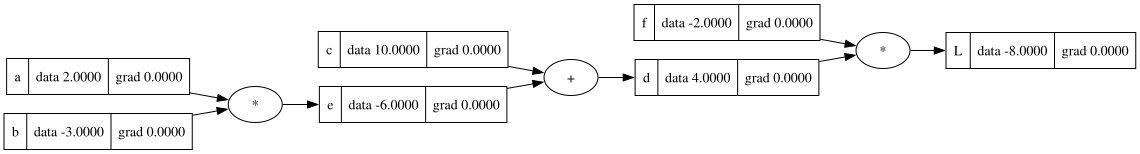

In [99]:
draw_dot(L)

Here grad value is the derivative of the loss function(i.e L) w.r.t to the node label  

In [100]:
# simply a function to see the gradients / dertivatives when each param is changed by h
def lol():

    h = 0.001

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    c = Value(10.0, label="c")
    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label="a")
    b = Value(-3.0, label="b")
    # here we are changing b by h and checking the gradient / derivative wrt to it i.e. dL/db
    b.data += h
    c = Value(10.0, label="c")
    e = a * b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    # this is effectively the derivative dL/db
    print((L2 - L1) / h)


lol()

-3.9999999999995595


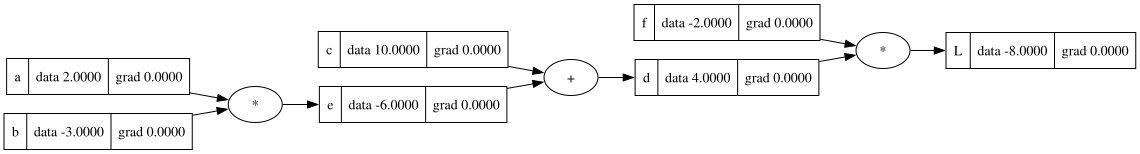

In [101]:
draw_dot(L)

ok so,
WE WANT: 
dL/dc

WE KNOW:
dL/dd 
dd/dc

THEN FROM CHAIN RULE:
dL/dc = ( dL / dd ) * ( dd / dc )

THIS IS BASICALLY BACK PROPAGATION 

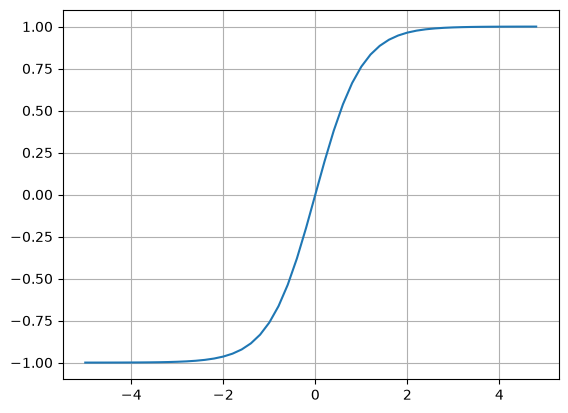

In [102]:
# simple plot to visualize the tanh activation function
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid();

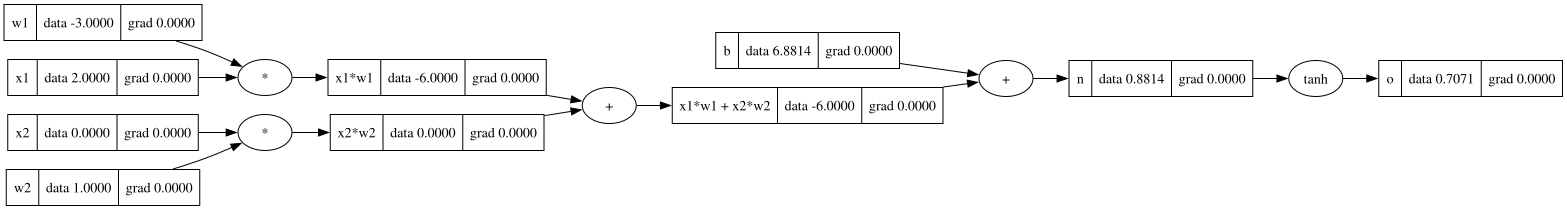

In [103]:
# example of a simple neural network with 2 inputs, with weights w1, w2, added with a bias b, which then passes through a tanh activation function

# visually: x1, x1 ---> *(w1, w2) --- +b ----> tanh(result)

# inputs x1,x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1,w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1*w1 + x2*w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"


n = x1w1x2w2 + b
n.label = "n"
o = n.tanh()
o.label = "o"

draw_dot(o)

In [104]:
o.grad = 1.0

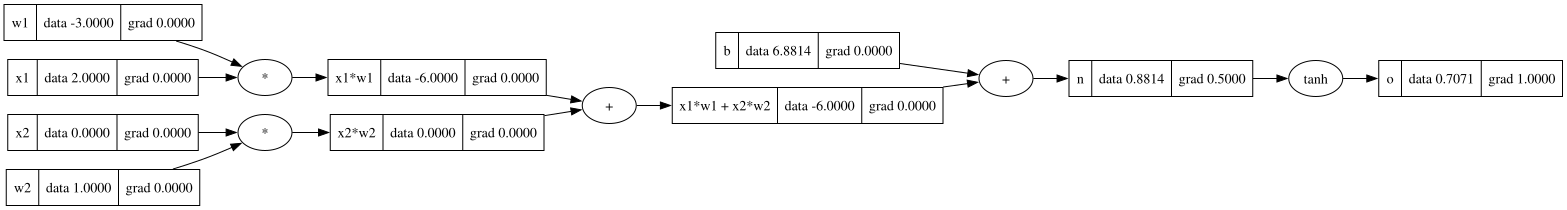

In [105]:
# we need to backpropagate, and how can we do that?
# ans: derivative of the function

# we have o i.e. o = tanh(n)
# so if we want to go one step back we do d(o)/d(n)
# we have: d0/dn = 1 - tanh ^ 2
#                  1 - o^2
# n.grad =  1 - o^2
n.grad = 1 - o.data**2  # i.e. ~0.5
draw_dot(o)

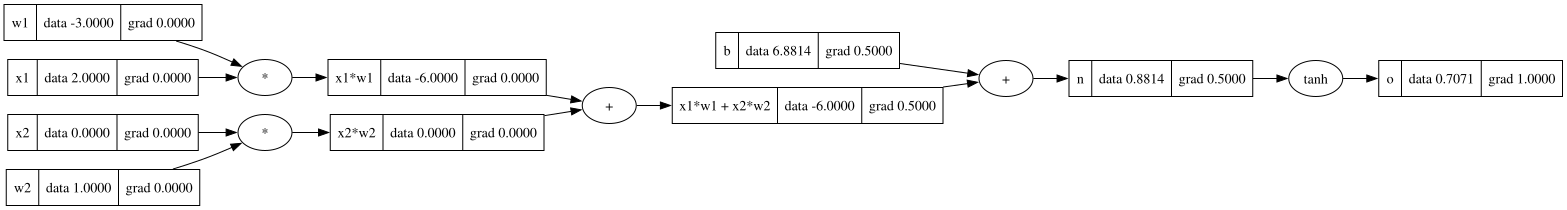

In [106]:
# since these nodes are just addition nodes, it has same gradient as the previous node
x1w1x2w2.grad = 0.5
b.grad = 0.5
draw_dot(o)

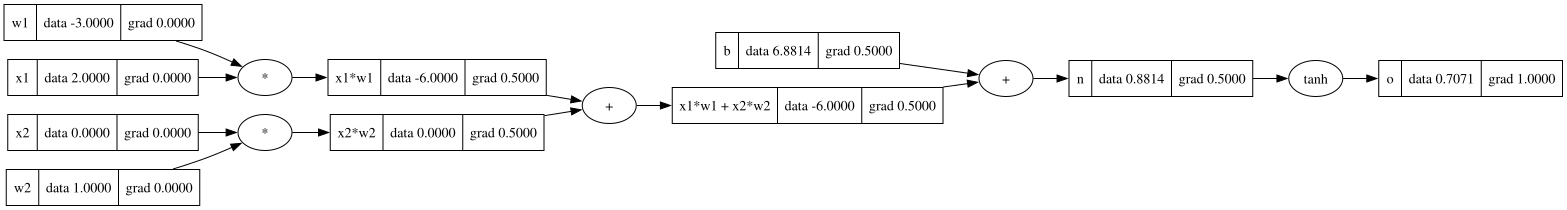

In [107]:
# again we have addition nodes, so the gradient flows backwards unchanged.
x1w1.grad = 0.5
x2w2.grad = 0.5
draw_dot(o)

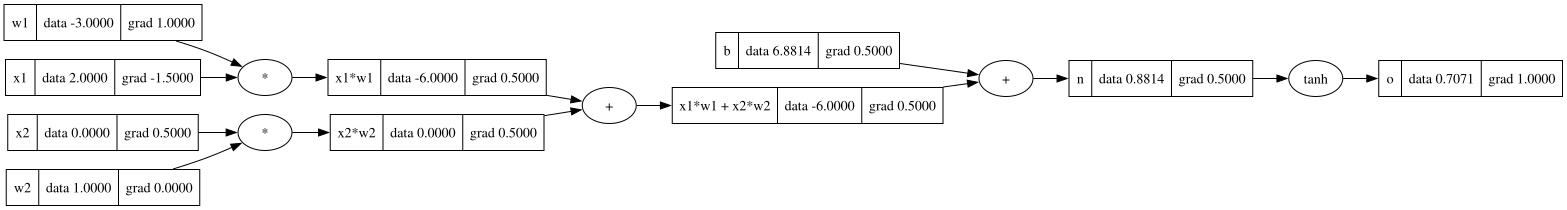

In [108]:
# now final step for the last stage i.e. multiplicative gradient
x1.grad = x1w1.grad * w1.data
x2.grad = x2w2.grad * w2.data

w1.grad = x1w1.grad * x1.data
w2.grad = x2w2.grad * x2.data

draw_dot(o)

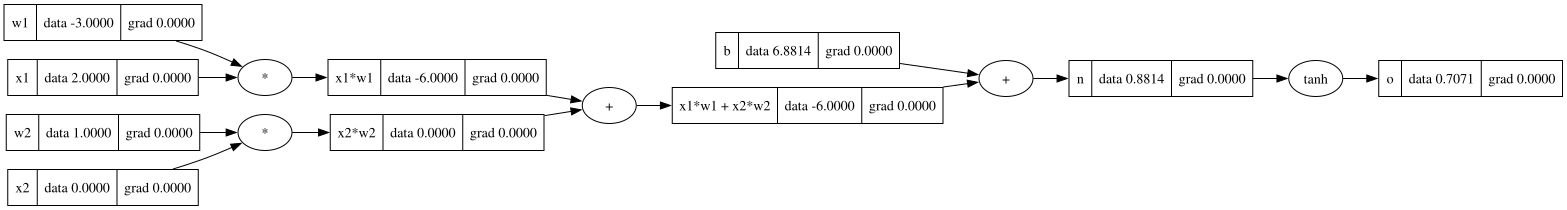

In [109]:
# now we added the backward operations to all operation inside the value class and re-initializing neuron with all gradients as zero.

# visually: x1, x1 ---> *(w1, w2) --- +b ----> tanh(result)

# inputs x1,x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1,w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1*w1 + x2*w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"


n = x1w1x2w2 + b
n.label = "n"
o = n.tanh()
o.label = "o"

draw_dot(o)

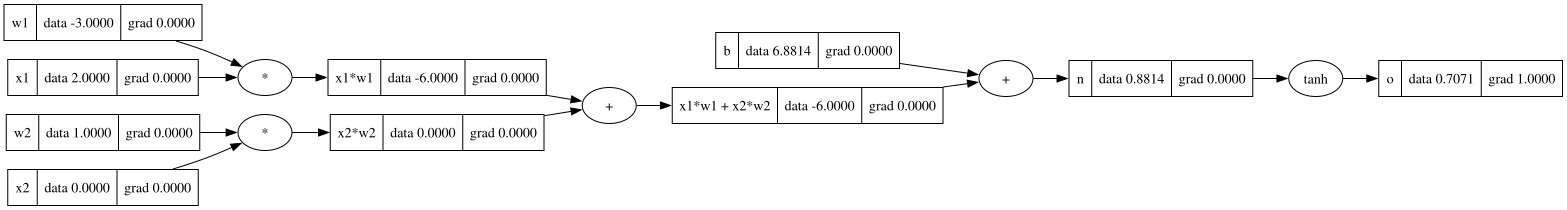

In [110]:
# initialize the initial o/p neuron gradient with 1
o.grad = 1.0
draw_dot(o)

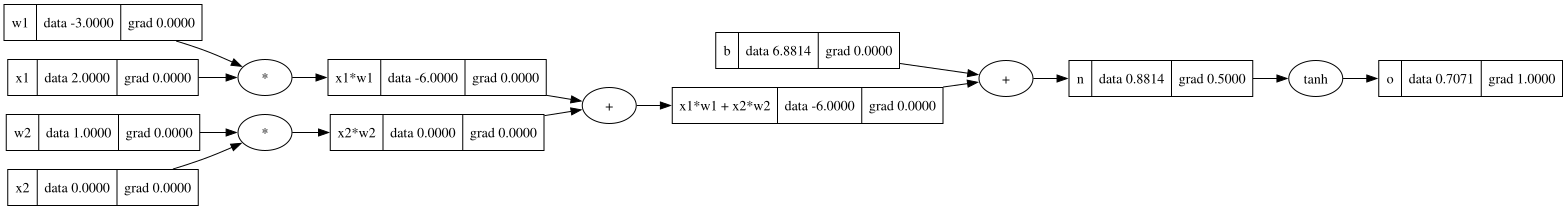

In [111]:
# this should backpropagate the tanh to n 
o._backward()
draw_dot(o)

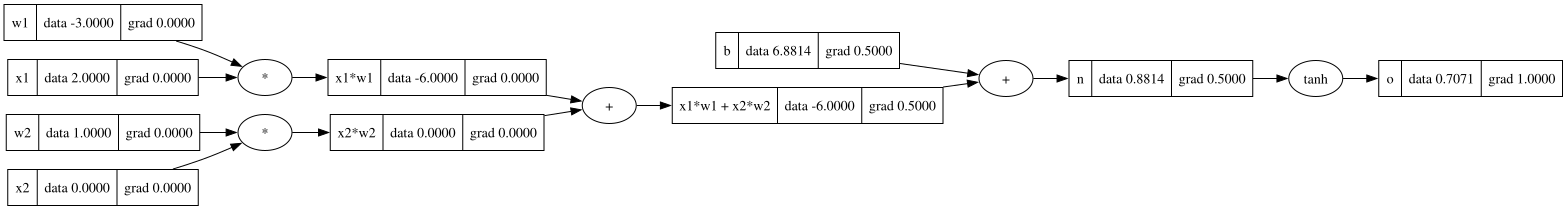

In [112]:
# now back propagating from node n 
n._backward()
draw_dot(o)

In [113]:
b._backward()

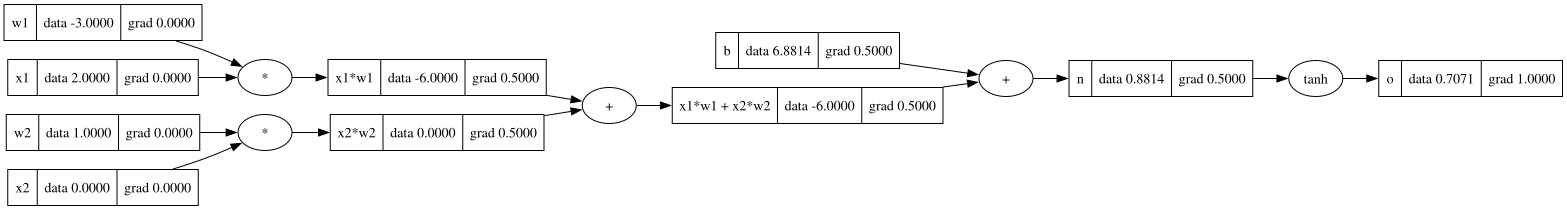

In [114]:
# now for x1w1x2w2
x1w1x2w2._backward()
draw_dot(o)

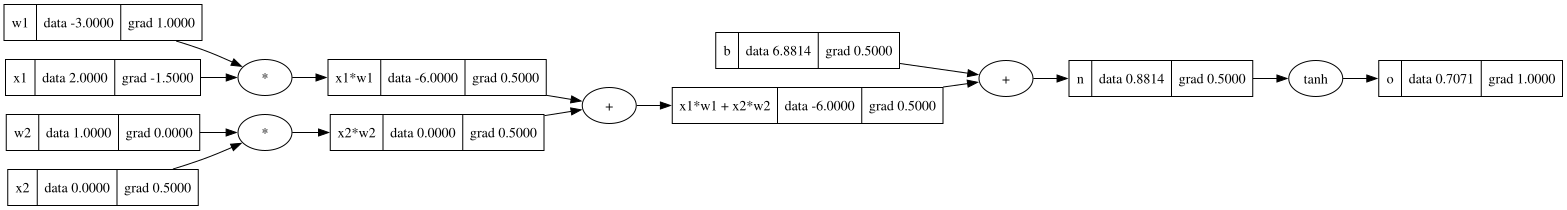

In [115]:
x1w1._backward()
x2w2._backward()
draw_dot(o)

As observed to get a gradient for a certain node the elements before it must be processed so we much approach the automated approach so that the order doesnot cause an node to be processed whos predecessor nodes have not been processed. 

we can achieve that using topological sort


In [116]:
topo = []
visited = set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)
topo

[Value(data = 6.881373587019543),
 Value(data = 1.0),
 Value(data = 0.0),
 Value(data = 0.0),
 Value(data = 2.0),
 Value(data = -3.0),
 Value(data = -6.0),
 Value(data = -6.0),
 Value(data = 0.8813735870195432),
 Value(data = 0.7071067811865476)]

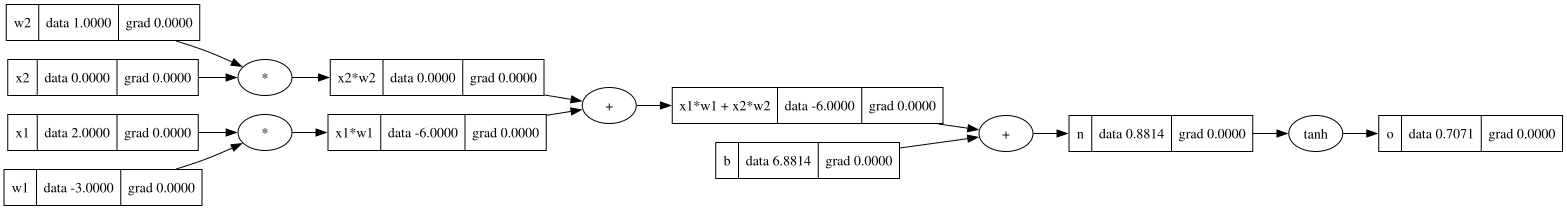

In [117]:
# now we can automate it by calling the back prop on the reversed list

# first reset the neuron gradient weights
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1,w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1*w1 + x2*w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"


n = x1w1x2w2 + b
n.label = "n"
o = n.tanh()
o.label = "o"

draw_dot(o)

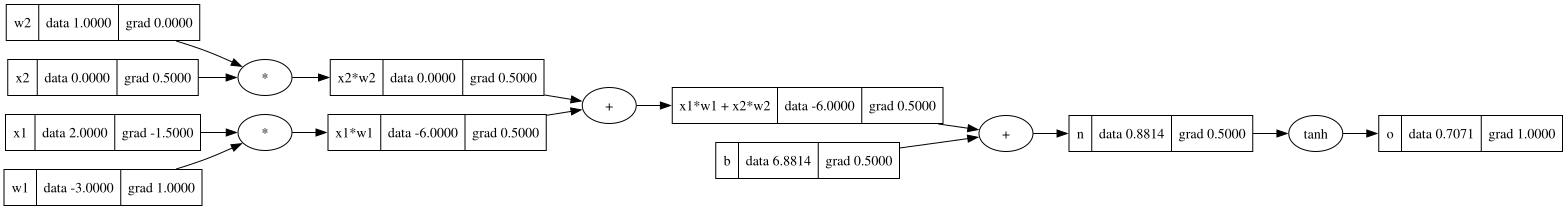

In [118]:
o.grad = 1.0

topo = []
visited = set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)

for node in reversed(topo):
  node._backward()

draw_dot(o)

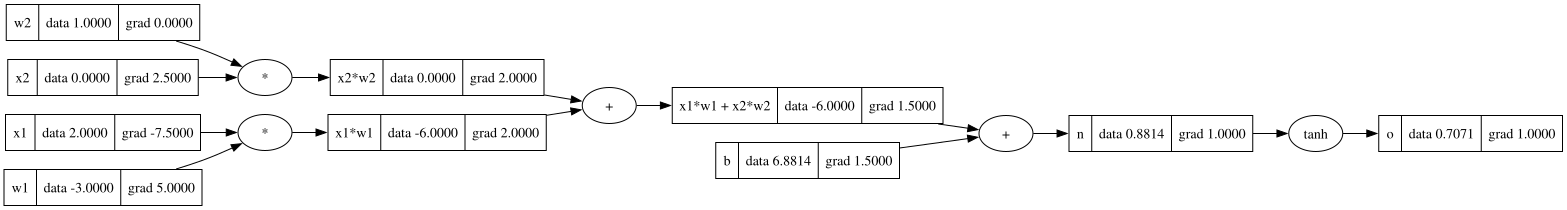

In [119]:
# and finally we can hide the functionality inside the Value class itself using the backward method
# remember to reset the neuron gradients before this.

o.backward()
draw_dot(o)

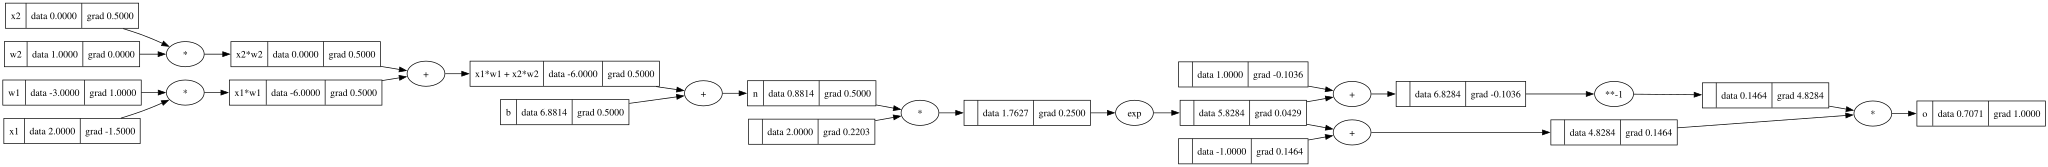

In [123]:
# now implementing using the tanh formula of exponents 

# first reset the neuron gradient weights
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1,w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
b = Value(6.8813735870195432, label="b")

# x1*w1 + x2*w2 + b
x1w1 = x1 * w1
x1w1.label = "x1*w1"
x2w2 = x2 * w2
x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1*w1 + x2*w2"


n = x1w1x2w2 + b
n.label = "n"
# ------------
e = (2*n).exp()
o = (e-1)/(e+1)
# using the subtract and exponent functions we created for replacing the tanh activation func
# ------------

o.label = "o"
o.backward()
draw_dot(o)